# Proximity Prototypes on Iris

This notebook demonstrates `get_prototypes` on the classic iris dataset loaded through `forestgap.datasets.load_openml_dataset`. Each prototype is a classwise proximity neighborhood summary: the selected center is the case whose `k` nearest proximity neighbors contain the largest number of same-class observations among the remaining training cases.

In [24]:
from pathlib import Path
import sys

for candidate in (Path.cwd(), Path.cwd() / "ObliqueProximitiesCode", Path.cwd().parent):
    if (candidate / "forestgap").exists():
        sys.path.insert(0, str(candidate))
        break

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.ensemble import RandomForestClassifier

from aeon.classification.sklearn import RotationForestClassifier

from forestgap import with_sparse_proximity
from forestgap.datasets import load_openml_dataset

## Load Iris from `forestgap.datasets`

We load the classic iris dataset by OpenML id so the target is the standard single species label rather than the newer one-hot-style variant that may resolve by name alone.

In [26]:
iris = load_openml_dataset(dataset_id=61, as_frame=True)
X = iris.X.copy()
y = iris.y.astype(str)

display(pd.DataFrame({
    "dataset": [iris.name],
    "dataset_id": [iris.dataset_id],
    "target_name": [iris.target_name],
    "n_samples": [X.shape[0]],
    "n_features": [X.shape[1]],
} ))
display(X.head())
y.value_counts().rename("count").to_frame()

,dataset,dataset_id,target_name,n_samples,n_features
0,iris,61,class,150,4


,sepallength,sepalwidth,petallength,petalwidth
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


,count
class,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


In [27]:
ProxRandomForestClassifier = with_sparse_proximity(RotationForestClassifier)
model = ProxRandomForestClassifier(
    n_estimators=300,
    random_state=42,
    prox_method="original",
    matrix_type="sparse",
    # bootstrap=False,
    # max_features=None,
)
model.fit(X, y)

prototypes = model.get_prototypes(
    k=10,
    n_prototypes=3,
)
standardized_prototypes = model.get_prototypes(
    k=10,
    n_prototypes=3,
    standardize_continuous=True,
)

In [28]:
def flatten_prototypes(prototypes_dict):
    rows = []
    for class_label, records in prototypes_dict.items():
        for record in records:
            row = {
                "class_label": class_label,
                "prototype_number": record["prototype_number"],
                "center_index": record["center_index"],
                "same_class_neighbor_count": record["same_class_neighbor_count"],
                "same_class_neighbor_fraction": record["same_class_neighbor_fraction"],
            }
            row.update(record["prototype"].to_dict())
            rows.append(row)
    return pd.DataFrame(rows)

prototype_table = flatten_prototypes(prototypes)
prototype_table

,class_label,prototype_number,center_index,same_class_neighbor_count,same_class_neighbor_fraction,sepallength,sepalwidth,petallength,petalwidth
0,Iris-setosa,1,0,10,1.0,4.90,3.30,1.40,0.20
1,Iris-setosa,2,10,10,1.0,5.25,3.75,1.45,0.25
2,Iris-setosa,3,20,10,1.0,5.05,3.40,1.60,0.20
3,Iris-versicolor,1,64,10,1.0,5.70,2.85,4.10,1.30
4,Iris-versicolor,2,91,10,1.0,6.25,2.95,4.45,1.40
5,Iris-versicolor,3,69,10,1.0,5.50,2.50,3.90,1.10
6,Iris-virginica,1,100,10,1.0,6.75,3.05,5.65,2.20
7,Iris-virginica,2,144,10,1.0,6.50,3.10,5.40,2.30
8,Iris-virginica,3,105,10,1.0,7.50,2.90,6.20,2.05


## Read the Prototype Table

Each row is one classwise prototype neighborhood. `center_index` is the original iris observation chosen as the prototype center, while the feature columns are the neighborhood medians. Because iris is fully numeric, all feature summaries come from the continuous summaries.

In [29]:
selected = prototypes["Iris-versicolor"][0]

print("Selected prototype:", selected["class_label"], "P", selected["prototype_number"], sep="")
print("Center index:", selected["center_index"])
print("Neighbor indices:", list(selected["neighbor_index"]))
display(selected["continuous_summary"])
display(X.loc[selected["neighbor_index"]].assign(species=y.loc[selected["neighbor_index"]]))

Selected prototype:Iris-versicolorP1
Center index: 64
Neighbor indices: [64, 79, 82, 88, 96, 99, 71, 94, 95, 97]


,q25,median,q75
feature,,,
sepallength,5.625,5.70,5.775
sepalwidth,2.725,2.85,2.900
petallength,3.925,4.10,4.200
petalwidth,1.225,1.30,1.300


,sepallength,sepalwidth,petallength,petalwidth,species
64,5.6,2.9,3.6,1.3,Iris-versicolor
79,5.7,2.6,3.5,1.0,Iris-versicolor
82,5.8,2.7,3.9,1.2,Iris-versicolor
88,5.6,3.0,4.1,1.3,Iris-versicolor
96,5.7,2.9,4.2,1.3,Iris-versicolor
99,5.7,2.8,4.1,1.3,Iris-versicolor
71,6.1,2.8,4.0,1.3,Iris-versicolor
94,5.6,2.7,4.2,1.3,Iris-versicolor
95,5.7,3.0,4.2,1.2,Iris-versicolor
97,6.2,2.9,4.3,1.3,Iris-versicolor


## Standardized Continuous Summaries

These values apply Breiman's output convention: subtract the training 5th percentile and divide by the 95th minus 5th percentile, feature by feature. This makes the prototype medians easier to compare across iris measurements with different units and spreads.

In [30]:
standardized_table = flatten_prototypes(standardized_prototypes)
standardized_table

,class_label,prototype_number,center_index,same_class_neighbor_count,same_class_neighbor_fraction,sepallength,sepalwidth,petallength,petalwidth
0,Iris-setosa,1,0,10,1.0,0.112994,0.656357,0.020833,0.000000
1,Iris-setosa,2,10,10,1.0,0.244821,0.965636,0.031250,0.023810
2,Iris-setosa,3,20,10,1.0,0.169492,0.725086,0.062500,0.000000
3,Iris-versicolor,1,64,10,1.0,0.414313,0.347079,0.583333,0.523810
4,Iris-versicolor,2,91,10,1.0,0.621469,0.415808,0.656250,0.571429
5,Iris-versicolor,3,69,10,1.0,0.338983,0.106529,0.541667,0.428571
6,Iris-virginica,1,100,10,1.0,0.809793,0.484536,0.906250,0.952381
7,Iris-virginica,2,144,10,1.0,0.715631,0.518900,0.854167,1.000000
8,Iris-virginica,3,105,10,1.0,1.092279,0.381443,1.020833,0.880952


## Plot 1: Prototype Feature Heatmap

This heatmap highlights which measurements are most characteristic of each prototype neighborhood after standardization.

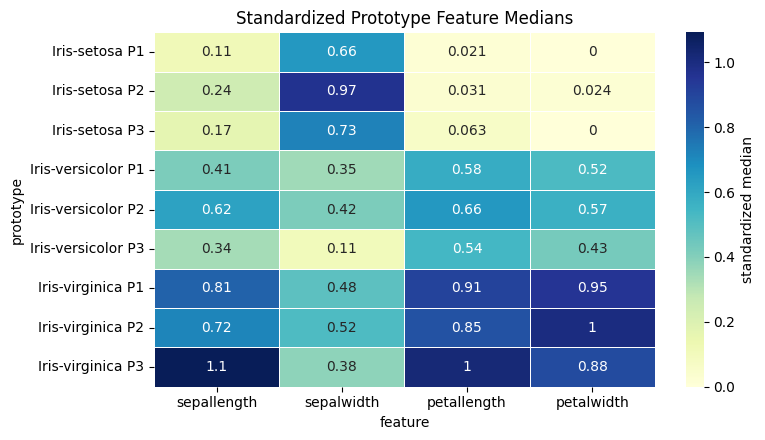

In [31]:
heatmap_df = standardized_table.copy()
heatmap_df["prototype_label"] = heatmap_df["class_label"] + " P" + heatmap_df["prototype_number"].astype(str)
heatmap_matrix = heatmap_df.set_index("prototype_label")[X.columns]

plt.figure(figsize=(8, 4.5))
sns.heatmap(heatmap_matrix, annot=True, cmap="YlGnBu", linewidths=0.5, cbar_kws={"label": "standardized median"})
plt.title("Standardized Prototype Feature Medians")
plt.xlabel("feature")
plt.ylabel("prototype")
plt.tight_layout()
plt.show()

## Plot 2: Prototype Centers in Petal Space

Petal length and petal width separate iris species particularly well. The colored circles are all observations, the black-ringed points are the prototype neighborhoods, and the large `X` markers are the selected prototype centers.

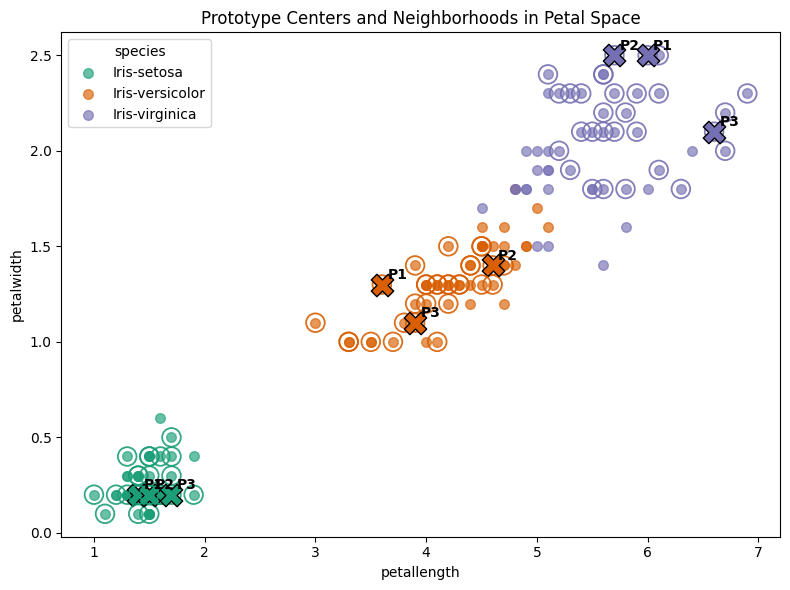

In [32]:
feature_x = "petallength"
feature_y = "petalwidth"
palette = {
    "Iris-setosa": "#1b9e77",
    "Iris-versicolor": "#d95f02",
    "Iris-virginica": "#7570b3",
}

fig, ax = plt.subplots(figsize=(8, 6))
for class_label, frame in X.assign(species=y).groupby("species"):
    ax.scatter(
        frame[feature_x],
        frame[feature_y],
        s=48,
        alpha=0.65,
        color=palette[class_label],
        label=class_label,
    )

for class_label, records in prototypes.items():
    for record in records:
        neighbor_idx = record["neighbor_index"]
        neighbor_points = X.loc[neighbor_idx, [feature_x, feature_y]]
        center_point = X.loc[record["center_index"], [feature_x, feature_y]]
        ax.scatter(
            neighbor_points[feature_x],
            neighbor_points[feature_y],
            s=180,
            facecolors="none",
            edgecolors=palette[class_label],
            linewidth=1.3,
            alpha=0.9,
        )
        ax.scatter(
            center_point[feature_x],
            center_point[feature_y],
            s=260,
            marker="X",
            color=palette[class_label],
            edgecolor="black",
            linewidth=1.0,
        )
        ax.text(
            center_point[feature_x] + 0.05,
            center_point[feature_y] + 0.03,
            f"P{record['prototype_number']}",
            fontsize=10,
            weight="bold",
        )

ax.set_title("Prototype Centers and Neighborhoods in Petal Space")
ax.set_xlabel(feature_x)
ax.set_ylabel(feature_y)
ax.legend(title="species")
plt.tight_layout()
plt.show()

## Plot 3: Prototype Centers Across All Four Measurements

This plot compares the raw feature medians of each prototype neighborhood and adds asymmetric error bars from the 25th to the 75th percentile. It makes it easy to see both the central prototype profile and how stable each feature is within that prototype neighborhood.

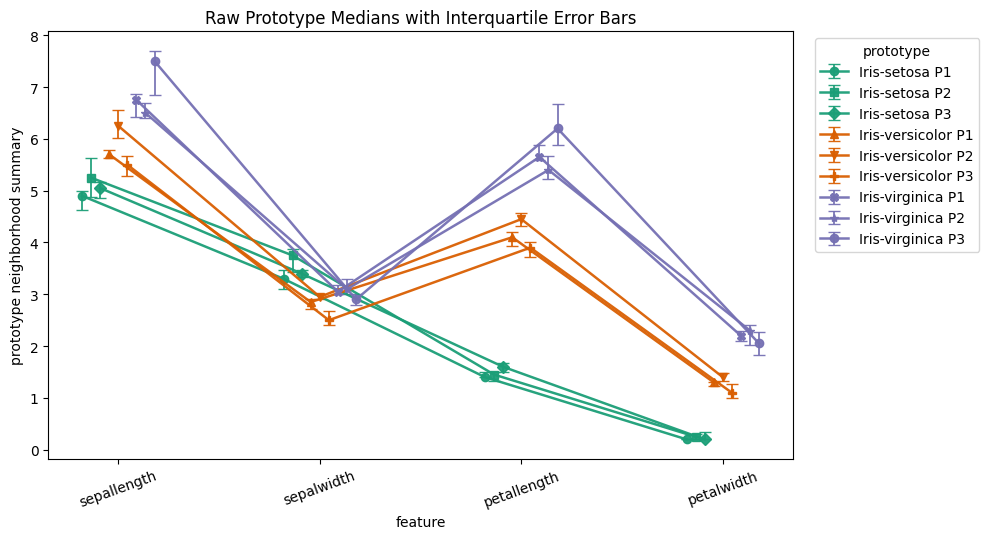

In [33]:
feature_summary_rows = []
for class_label, records in prototypes.items():
    for record in records:
        summary = record["continuous_summary"].reset_index().copy()
        summary["class_label"] = class_label
        summary["prototype_number"] = record["prototype_number"]
        summary["prototype_label"] = f"{class_label} P{record['prototype_number']}"
        feature_summary_rows.append(summary)

feature_summary_df = pd.concat(feature_summary_rows, ignore_index=True)
feature_order = list(X.columns)
x_positions = np.arange(len(feature_order), dtype=float)
prototype_labels = feature_summary_df["prototype_label"].drop_duplicates().tolist()
offsets = np.linspace(-0.18, 0.18, len(prototype_labels)) if len(prototype_labels) > 1 else np.array([0.0])
markers = ["o", "s", "D", "^", "v", "P", "X", "*"]

fig, ax = plt.subplots(figsize=(10, 5.5))
for idx, prototype_label in enumerate(prototype_labels):
    subset = (
        feature_summary_df[feature_summary_df["prototype_label"] == prototype_label]
        .set_index("feature")
        .loc[feature_order]
        .reset_index()
    )
    class_label = subset["class_label"].iloc[0]
    medians = subset["median"].to_numpy(dtype=float)
    q25 = subset["q25"].to_numpy(dtype=float)
    q75 = subset["q75"].to_numpy(dtype=float)
    yerr = np.vstack([medians - q25, q75 - medians])
    ax.errorbar(
        x_positions + offsets[idx],
        medians,
        yerr=yerr,
        color=palette[class_label],
        marker=markers[idx % len(markers)],
        markersize=6,
        linewidth=1.8,
        elinewidth=1.3,
        capsize=4,
        alpha=0.95,
        label=prototype_label,
    )

ax.set_title("Raw Prototype Medians with Interquartile Error Bars")
ax.set_xlabel("feature")
ax.set_ylabel("prototype neighborhood summary")
ax.set_xticks(x_positions)
ax.set_xticklabels(feature_order, rotation=20)
ax.legend(title="prototype", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Prototype Probabilities Versus Same-Class Peers

The prototype centers are training observations, so their direct `predict_proba` values can be optimistic. To put those values in context, this section fits a separate bootstrap random forest with OOB scoring enabled. We then compare each prototype center's class probability to:

1. the in-sample `predict_proba` distribution for other observations in the same class, and
2. the OOB class-probability distribution for non-prototype observations in the same class.

This gives a clearer sense of whether the prototype centers are unusually representative even under a held-out-style OOB view. The OOB comparison model is a proximity-wrapped `RandomForestClassifier`, since OOB probabilities are not available for the rotation-forest prototype fit above.

In [ ]:
ProxOOBRandomForestClassifier = with_sparse_proximity(RandomForestClassifier)
comparison_model = ProxOOBRandomForestClassifier(
    n_estimators=400,
    random_state=123,
    prox_method="original",
    matrix_type="sparse",
    bootstrap=True,
    oob_score=True,
    max_features=None,
)
comparison_model.fit(X, y)

comparison_classes = list(comparison_model.classes_)
predict_proba_df = pd.DataFrame(
    comparison_model.predict_proba(X),
    index=X.index,
    columns=comparison_classes,
)
oob_proba_df = pd.DataFrame(
    comparison_model.oob_decision_function_,
    index=X.index,
    columns=comparison_classes,
)

prototype_centers_by_class = {
    class_label: [record["center_index"] for record in records]
    for class_label, records in prototypes.items()
}

probability_rows = []
for class_label, records in prototypes.items():
    class_idx = y.index[y == class_label]
    same_class_predict = predict_proba_df.loc[class_idx, class_label]
    nonprototype_idx = class_idx.difference(pd.Index(prototype_centers_by_class[class_label]))
    nonprototype_oob = oob_proba_df.loc[nonprototype_idx, class_label]

    for record in records:
        center_index = record["center_index"]
        prototype_predict = float(predict_proba_df.loc[center_index, class_label])
        prototype_oob = float(oob_proba_df.loc[center_index, class_label])
        same_class_predict_others = same_class_predict.drop(index=center_index)

        probability_rows.append(
            {
                "class_label": class_label,
                "prototype_number": record["prototype_number"],
                "center_index": center_index,
                "prototype_predict_proba": prototype_predict,
                "prototype_oob_proba": prototype_oob,
                "same_class_predict_median": float(same_class_predict_others.median()),
                "same_class_predict_q25": float(same_class_predict_others.quantile(0.25)),
                "same_class_predict_q75": float(same_class_predict_others.quantile(0.75)),
                "nonprototype_oob_median": float(nonprototype_oob.median()),
                "nonprototype_oob_q25": float(nonprototype_oob.quantile(0.25)),
                "nonprototype_oob_q75": float(nonprototype_oob.quantile(0.75)),
                "predict_percentile_within_class": float((same_class_predict_others <= prototype_predict).mean()),
                "predict_percentile_vs_nonprototype_oob": float((nonprototype_oob <= prototype_predict).mean()),
                "oob_percentile_vs_nonprototype_oob": float((nonprototype_oob <= prototype_oob).mean()),
            }
        )

probability_summary = pd.DataFrame(probability_rows).sort_values(["class_label", "prototype_number"])
probability_summary

In [ ]:
for row in probability_summary.itertuples(index=False):
    print(
        f"{row.class_label} P{row.prototype_number} (index {row.center_index}): "
        f"predict_proba={row.prototype_predict_proba:.3f}, "
        f"prototype OOB={row.prototype_oob_proba:.3f}, "
        f"same-class predict median={row.same_class_predict_median:.3f}, "
        f"non-prototype OOB median={row.nonprototype_oob_median:.3f}, "
        f"predict percentile within class={row.predict_percentile_within_class:.2%}, "
        f"predict percentile versus non-prototype OOB={row.predict_percentile_vs_nonprototype_oob:.2%}, "
        f"prototype OOB percentile versus non-prototype OOB={row.oob_percentile_vs_nonprototype_oob:.2%}."
    )

In [ ]:
oob_background_rows = []
for class_label in comparison_classes:
    class_idx = y.index[y == class_label]
    nonprototype_idx = class_idx.difference(pd.Index(prototype_centers_by_class[class_label]))
    for idx in nonprototype_idx:
        oob_background_rows.append(
            {
                "class_label": class_label,
                "probability": float(oob_proba_df.loc[idx, class_label]),
            }
        )

oob_background_df = pd.DataFrame(oob_background_rows)
class_order = comparison_classes
x_map = {label: pos for pos, label in enumerate(class_order)}
prototype_offsets = np.linspace(-0.12, 0.12, probability_summary.shape[0] // len(class_order))

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(
    data=oob_background_df,
    x="class_label",
    y="probability",
    order=class_order,
    color="#d9e6f2",
    showfliers=False,
    width=0.55,
    ax=ax,
)
sns.stripplot(
    data=oob_background_df,
    x="class_label",
    y="probability",
    order=class_order,
    color="#6c7a89",
    alpha=0.35,
    jitter=0.18,
    size=4,
    ax=ax,
)

for class_label in class_order:
    class_rows = probability_summary[probability_summary["class_label"] == class_label].reset_index(drop=True)
    for idx, row in class_rows.iterrows():
        x_pos = x_map[class_label] + prototype_offsets[idx]
        ax.scatter(
            x_pos,
            row["prototype_predict_proba"],
            marker="X",
            s=180,
            color=palette[class_label],
            edgecolor="black",
            linewidth=0.9,
            zorder=5,
        )
        ax.scatter(
            x_pos,
            row["prototype_oob_proba"],
            marker="D",
            s=90,
            color=palette[class_label],
            edgecolor="black",
            linewidth=0.8,
            zorder=5,
        )
        ax.text(
            x_pos + 0.02,
            row["prototype_predict_proba"] + 0.015,
            f"P{int(row['prototype_number'])}",
            fontsize=9,
        )

from matplotlib.lines import Line2D
legend_handles = [
    Line2D([0], [0], marker="X", color="w", markerfacecolor="gray", markeredgecolor="black", markersize=10, linestyle="None", label="prototype predict_proba"),
    Line2D([0], [0], marker="D", color="w", markerfacecolor="gray", markeredgecolor="black", markersize=8, linestyle="None", label="prototype OOB probability"),
]
ax.legend(handles=legend_handles, loc="lower right")
ax.set_title("Prototype Class Probabilities Versus Same-Class OOB Peers")
ax.set_xlabel("species")
ax.set_ylabel("probability assigned to the true class")
plt.tight_layout()
plt.show()